--- BẢNG TÍNH TOÁN VÍ DỤ 5.5 (trang 108 SGK) ---
 j    x_j   p_j    z_j
 1  5.510 0.020 -2.054
 2  6.060 0.060 -1.555
 3  6.170 0.100 -1.282
 4  8.520 0.140 -1.080
 5  8.790 0.180 -0.915
 6  9.830 0.220 -0.772
 7  9.950 0.260 -0.643
 8  9.960 0.300 -0.524
 9 10.060 0.340 -0.412
10 10.150 0.380 -0.305
11 10.770 0.420 -0.202
12 10.870 0.460 -0.100
13 11.070 0.500  0.000
14 11.120 0.540  0.100
15 11.250 0.580  0.202
16 11.270 0.620  0.305
17 11.310 0.660  0.412
18 11.810 0.700  0.524
19 11.890 0.740  0.643
20 12.020 0.780  0.772
21 12.080 0.820  0.915
22 13.920 0.860  1.080
23 13.950 0.900  1.282
24 14.640 0.940  1.555
25 15.670 0.980  2.054


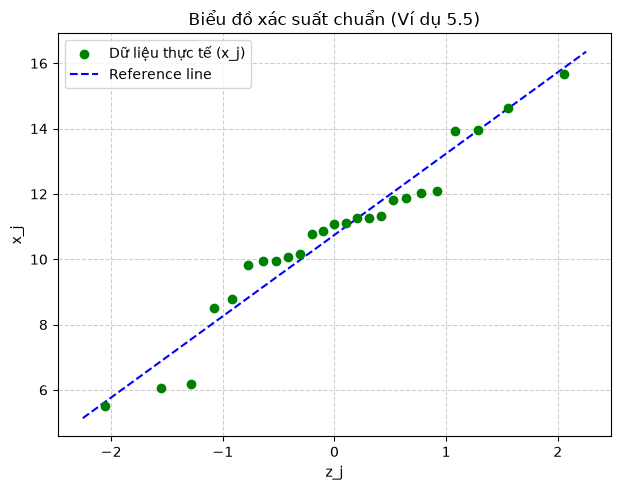


--- KẾT QUẢ ƯỚC LƯỢNG VÍ DỤ 5.5 trang 108 SGK---
Trung bình mẫu            : 10.75
Độ lệch chuẩn mẫu (s)     : 2.49
Giá trị t_(24; 0.025)     : 2.0639
Sai số ước lượng của mẫu  : 1.03
Khoảng tin cậy 95% của mu : (9.72 < mu < 11.77)


In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.stats import norm, t

# 1. Khai báo trực tiếp 25 số liệu gốc từ đề bài Ví dụ 5.5 trang 108 SGK và sắp xếp tăng dần
data_goc = [
    6.06, 11.07, 10.77, 15.67, 10.15, 
    5.51, 10.87, 12.02, 12.08, 6.17, 
    9.96, 9.95, 13.95, 10.06, 11.25, 
    8.79, 8.52, 11.31, 13.92, 11.81, 
    11.27, 11.12, 11.89, 14.64, 9.83
]
x_j = np.sort(data_goc)

# 2. Tính các đại lượng đặc trưng mẫu
n = len(x_j)
x_tb = np.mean(x_j)
s = np.std(x_j, ddof=1)

# 3. Tính bảng thông số cho Biểu đồ xác suất chuẩn
j = np.arange(1, n + 1)
p_j = (j - 0.5) / n
z_j = norm.ppf(p_j)

df = pd.DataFrame({'j': j, 'x_j': x_j, 'p_j': p_j, 'z_j': z_j})
print("--- BẢNG TÍNH TOÁN VÍ DỤ 5.5 (trang 108 SGK) ---")
print(df.to_string(index=False, float_format="%.3f"))

# 5. Vẽ biểu đồ
plt.figure(figsize=(12, 5))

# Biểu đồ xác suất chuẩn
plt.subplot(1, 2, 2)
plt.scatter(z_j, x_j, color='green', zorder=5, label='Dữ liệu thực tế (x_j)')
z_ends = np.array([min(z_j) - 0.2, max(z_j) + 0.2])
plt.plot(z_ends, s * z_ends + x_tb, 'b--', label='Reference line')
plt.title('Biểu đồ xác suất chuẩn (Ví dụ 5.5)')
plt.xlabel('z_j')
plt.ylabel('x_j')
plt.legend()
plt.grid(True, linestyle='--', alpha=0.6)

plt.tight_layout()
plt.show()

# 4. Tính khoảng tin cậy 95% (Phân phối Student t với bậc tự do df = n - 1 = 24)
alpha = 0.05
t_alpha_2 = t.ppf(1 - alpha / 2, df=n - 1)
epsilon = t_alpha_2 * (s / np.sqrt(n))
can_duoi = x_tb - epsilon
can_tren = x_tb + epsilon

print(f"\n--- KẾT QUẢ ƯỚC LƯỢNG VÍ DỤ 5.5 trang 108 SGK---")
print(f"Trung bình mẫu            : {x_tb:.2f}")
print(f"Độ lệch chuẩn mẫu (s)     : {s:.2f}")
print(f"Giá trị t_(24; 0.025)     : {t_alpha_2:.4f}")
print(f"Sai số ước lượng của mẫu  : {epsilon:.2f}")
print(f"Khoảng tin cậy 95% của mu : ({can_duoi:.2f} < mu < {can_tren:.2f})")
